In [1]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
topics = ["stance_abortion", "stance_atheism", "stance_climate", "stance_feminist", "stance_hillary"]

# Load the dataset
dataset = load_dataset("cardiffnlp/tweet_eval", topics[0]) # change for different stance

# Convert to Pandas DataFrames
#combine train and validation into one dataframe for training and testing
df_train = pd.concat([dataset["train"].to_pandas(), dataset["validation"].to_pandas()])
df_test = dataset["test"].to_pandas()

# Display the data
print("Training samples:", len(df_train))
print("Test samples:", len(df_test))

display(df_train.head())

Training samples: 653
Test samples: 280


,text,label
0,we remind ourselves that love means to be will...,1
1,@user @user and most Islanders have different ...,0
2,"Life is #precious & so are babies, mothers, & ...",1
3,@user too many people are taking this to serio...,0
4,Dude i won a #freeshirt from @user ! I never w...,0


Number of tweets per stance:
label_name
Against           355
None / Neutral    177
Favor             121
Name: count, dtype: int64


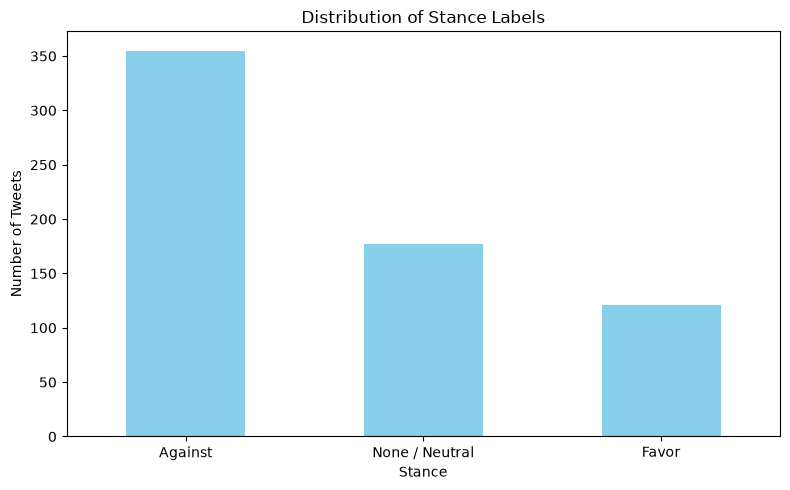

In [3]:
# Map numerical labels to stance names
label_names = {
    0: "None / Neutral",
    1: "Against",
    2: "Favor"
}

df_train["label_name"] = df_train["label"].map(label_names)

# Count tweets per stance
counts = df_train["label_name"].value_counts()

print("Number of tweets per stance:")
print(counts)

# Visualize the distribution
plt.figure(figsize=(8, 5))
counts.plot(kind="bar", color="skyblue")

plt.title("Distribution of Stance Labels")
plt.xlabel("Stance")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [4]:
for topic in topics:
    dataset = load_dataset("cardiffnlp/tweet_eval", topic)
    df_test = dataset["test"].to_pandas()
    counts = df_test["label"].value_counts()
    print(topic)
    print(f"Neutral: {counts.get(0, 0)}, Against: {counts.get(1, 0)}, Favor: {counts.get(2, 0)}")

stance_abortion
Neutral: 45, Against: 189, Favor: 46
stance_atheism
Neutral: 28, Against: 160, Favor: 32
stance_climate
Neutral: 35, Against: 11, Favor: 123
stance_feminist
Neutral: 44, Against: 183, Favor: 58
stance_hillary
Neutral: 78, Against: 172, Favor: 45


TEXT LENGTH STATISTICS
Total instances: 4163
Average words: 16.28
Median words: 17
Minimum words: 6
Maximum words: 31

Average words per topic:
           mean  min  max
topic                    
abortion  16.45    6   30
atheism   17.14    6   31
climate   15.60    6   26
feminist  16.68    6   28
hillary   15.50    6   28


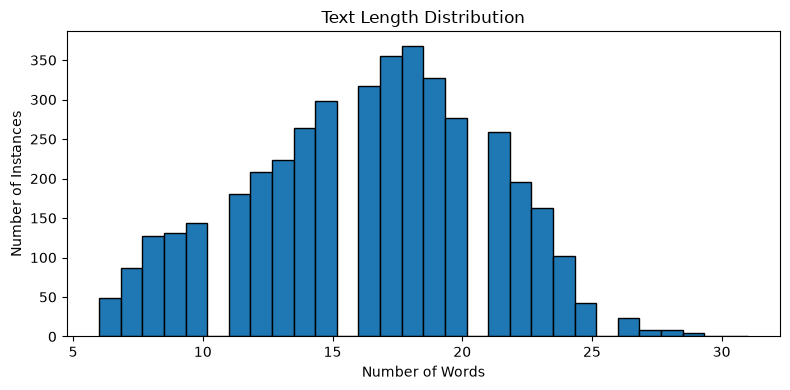


TEXT CHARACTERISTICS
           Count  Percentage
Hashtags  2486.0       59.72
Mentions  1628.0       39.11


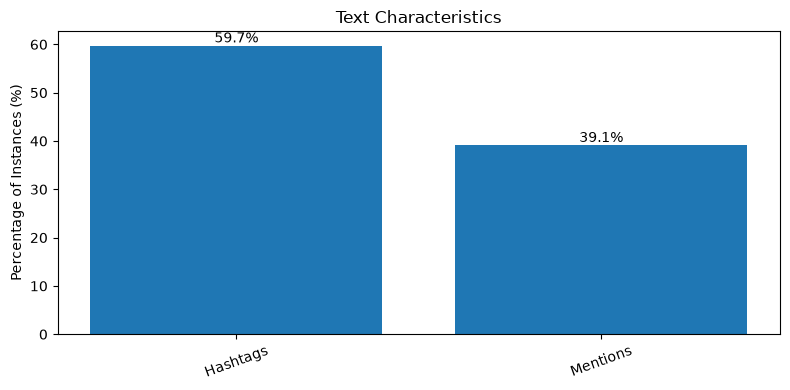

In [9]:
# Combine all topics and splits
all_data = []

for topic in topics:
    dataset = load_dataset("cardiffnlp/tweet_eval", topic)
    dataset = dataset.map(lambda x: {"text": x["text"].replace(" #SemST", "")})

    for split in ["train", "validation", "test"]:
        df = dataset[split].to_pandas()
        df["topic"] = topic.replace("stance_", "")
        df["split"] = split
        all_data.append(df)

df_all = pd.concat(all_data, ignore_index=True)

# --------------------------------------------------
# 1. TEXT LENGTH DISTRIBUTION
# --------------------------------------------------

df_all["word_count"] = df_all["text"].str.split().str.len()

print("TEXT LENGTH STATISTICS")
print(f"Total instances: {len(df_all)}")
print(f"Average words: {df_all['word_count'].mean():.2f}")
print(f"Median words: {df_all['word_count'].median():.0f}")
print(f"Minimum words: {df_all['word_count'].min()}")
print(f"Maximum words: {df_all['word_count'].max()}")

print("\nAverage words per topic:")
print(df_all.groupby("topic")["word_count"].agg(
    ["mean", "min", "max"]
).round(2))

plt.figure(figsize=(8, 4))
plt.hist(df_all["word_count"], bins=30, edgecolor="black")
plt.title("Text Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Instances")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 2. TEXT CHARACTERISTICS
# --------------------------------------------------

text = df_all["text"].fillna("")

features = {
    "Hashtags": r"(?<!\w)#[A-Za-z0-9_]+",
    "Mentions": r"(?<!\w)@[A-Za-z0-9_]+",
}

results = {}

for feature, pattern in features.items():
    matches = text.str.contains(
        pattern, case=False, regex=True
    )
    results[feature] = {
        "Count": matches.sum(),
        "Percentage": matches.mean() * 100
    }

feature_df = pd.DataFrame(results).T

print("\nTEXT CHARACTERISTICS")
print(feature_df.round(2))

plt.figure(figsize=(8, 4))
bars = plt.bar(
    feature_df.index,
    feature_df["Percentage"]
)

plt.title("Text Characteristics")
plt.ylabel("Percentage of Instances (%)")
plt.xticks(rotation=20)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()